In [2]:
"""
 competitive circuit -> drift-diffusion.

Model (time in units of the rate time constant):
    dr1/dt = -r1 + ws*r1 - wc*r2 + I0 + mu/2 + sigma*xi1(t)
    dr2/dt = -r2 + ws*r2 - wc*r1 + I0 - mu/2 + sigma*xi2(t)
Decision: the first time |r1 - r2| >= theta. 
Correct if r1 - r2 > 0
"""
import numpy as np
from scipy.integrate import trapezoid, cumulative_trapezoid
from scipy.stats import norm
import matplotlib.pyplot as plt


mu = 0.2            # evidence strength (favors population 1)
sigma = 0.5         # noise strength
I0 = 5.0            # common input
dt = 0.002          # Euler-Maruyama time step
n_trials = 10_000   # trials per threshold
thetas = [0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0]
lambdas = [0.0, 0.2]

rng = np.random.default_rng(4370)

#  simulate the two-population model

def simulate(lam, theta):
    ws = (1 + lam) / 2
    wc = (1 + lam) / 2

    r1 = np.full(n_trials, I0)            # every trial starts at r1 = r2 = I0
    r2 = np.full(n_trials, I0)
    decided = np.zeros(n_trials, dtype=bool)
    correct = np.zeros(n_trials, dtype=bool)
    decision_time = np.zeros(n_trials)
    t = 0.0

    while not decided.all():
        # drift part of each equation (the right-hand side without noise)
        drift1 = -r1 + ws * r1 - wc * r2 + I0 + mu / 2
        drift2 = -r2 + ws * r2 - wc * r1 + I0 - mu / 2

        # Euler-Maruyama: r(t+dt) = r(t) + dt*drift + sigma*sqrt(dt)*Z,  Z ~ Normal(0, 1)
        r1 = r1 + dt * drift1 + sigma * np.sqrt(dt) * rng.standard_normal(n_trials)
        r2 = r2 + dt * drift2 + sigma * np.sqrt(dt) * rng.standard_normal(n_trials)
        t = t + dt

        # which trials just crossed the threshold for the first time?
        d = r1 - r2
        just_hit = (np.abs(d) >= theta) & (~decided)

        correct[just_hit] = d[just_hit] > 0      # crossed +theta means chose population 1
        decision_time[just_hit] = t
        decided[just_hit] = True

    return correct, decision_time


# perfect integrator (lambda = 0)

def theory_b(theta):
    accuracy = 1 / (1 + np.exp(-mu * theta / sigma**2))
    mean_time = (theta / mu) * np.tanh(mu * theta / (2 * sigma**2))
    return accuracy, mean_time


# unstable circuit (lambda > 0), done with numerical integrals

def theory_c(lam, theta, n_points=4001):
    y = np.linspace(-theta, theta, n_points)          # grid from -theta to +theta
    exponent = (lam * y**2 + 2 * mu * y) / (2 * sigma**2)
    g = np.exp(-exponent)                              # g(y) from part (c)
    h = np.exp(+exponent)                              # h(y) = 1 / g(y)

    # accuracy: P = (integral of g from -theta to 0) / (integral of g from -theta to theta)
    left_half = y <= 0
    accuracy = trapezoid(g[left_half], y[left_half]) / trapezoid(g, y)

    # mean time: solve sigma^2 T'' + (lam*y + mu) T' = -1 with T(-theta) = T(theta) = 0
    H = cumulative_trapezoid(h, y, initial=0)          # H(y) = integral of h from -theta to y
    C = trapezoid(g * H, y) / (sigma**2 * trapezoid(g, y))
    T = cumulative_trapezoid(g * (C - H / sigma**2), y, initial=0)   # T(y)
    mean_time = np.interp(0.0, y, T)                   # we start at d = 0

    return accuracy, mean_time


#  Compare lambda = 0.2, theta = 4 with a perfect integrator of equal accuracy
acc_unstable, time_unstable = theory_c(0.2, 4.0)

# invert P = 1 / (1 + exp(-mu*theta/sigma^2)) to get theta = (sigma^2/mu) * ln(P / (1 - P))
theta_equal = (sigma**2 / mu) * np.log(acc_unstable / (1 - acc_unstable))
acc_equal, time_equal = theory_b(theta_equal)

print(f"unstable circuit, theta = 4:       accuracy {acc_unstable:.4f}, <T> = {time_unstable:.3f}")
print(f"perfect integrator, theta = {theta_equal:.3f}: accuracy {acc_equal:.4f}, <T> = {time_equal:.3f}")

correct, times = simulate(0.0, theta_equal)
print(f"perfect integrator simulated:       accuracy {correct.mean():.4f}, <T> = {times.mean():.3f}")



unstable circuit, theta = 4:       accuracy 0.8138, <T> = 8.231
perfect integrator, theta = 1.843: accuracy 0.8138, <T> = 5.784
perfect integrator simulated:       accuracy 0.8096, <T> = 5.930


In [3]:
results = {}   # results[(lam, theta)] = (accuracy, accuracy_error, mean_time, time_error)

for lam in lambdas:
    for theta in thetas:
        correct, times = simulate(lam, theta)

        accuracy = correct.mean()                                   # fraction correct
        accuracy_err = np.sqrt(accuracy * (1 - accuracy) / n_trials)
        mean_time = times.mean()
        time_err = times.std(ddof=1) / np.sqrt(n_trials)
        results[(lam, theta)] = (accuracy, accuracy_err, mean_time, time_err)

        if lam == 0:
            acc_theory, time_theory = theory_b(theta)
        else:
            acc_theory, time_theory = theory_c(lam, theta)

        print(f"lambda={lam}, theta={theta}: accuracy {accuracy:.4f} +- {accuracy_err:.4f} (theory {acc_theory:.4f}), "
              f"<T> {mean_time:.3f} +- {time_err:.3f} (theory {time_theory:.3f})")

ceiling = norm.cdf(mu / (sigma * np.sqrt(0.2)))
print(f"accuracy ceiling for lambda = 0.2: Phi(mu / (sigma sqrt(lambda))) = {ceiling:.4f}")



lambda=0.0, theta=0.5: accuracy 0.6080 +- 0.0049 (theory 0.5987), <T> 0.527 +- 0.004 (theory 0.493)
lambda=0.0, theta=1.0: accuracy 0.6954 +- 0.0046 (theory 0.6900), <T> 1.975 +- 0.016 (theory 1.900)
lambda=0.0, theta=1.5: accuracy 0.7747 +- 0.0042 (theory 0.7685), <T> 4.142 +- 0.034 (theory 4.028)
lambda=0.0, theta=2.0: accuracy 0.8316 +- 0.0037 (theory 0.8320), <T> 6.708 +- 0.052 (theory 6.640)
lambda=0.0, theta=2.5: accuracy 0.8837 +- 0.0032 (theory 0.8808), <T> 9.585 +- 0.074 (theory 9.520)
lambda=0.0, theta=3.0: accuracy 0.9190 +- 0.0027 (theory 0.9168), <T> 12.679 +- 0.096 (theory 12.505)
lambda=0.0, theta=3.5: accuracy 0.9447 +- 0.0023 (theory 0.9427), <T> 15.642 +- 0.113 (theory 15.494)
lambda=0.0, theta=4.0: accuracy 0.9620 +- 0.0019 (theory 0.9608), <T> 18.409 +- 0.128 (theory 18.433)
lambda=0.2, theta=0.5: accuracy 0.5969 +- 0.0049 (theory 0.5971), <T> 0.517 +- 0.004 (theory 0.478)
lambda=0.2, theta=1.0: accuracy 0.6812 +- 0.0047 (theory 0.6789), <T> 1.714 +- 0.014 (theory 1

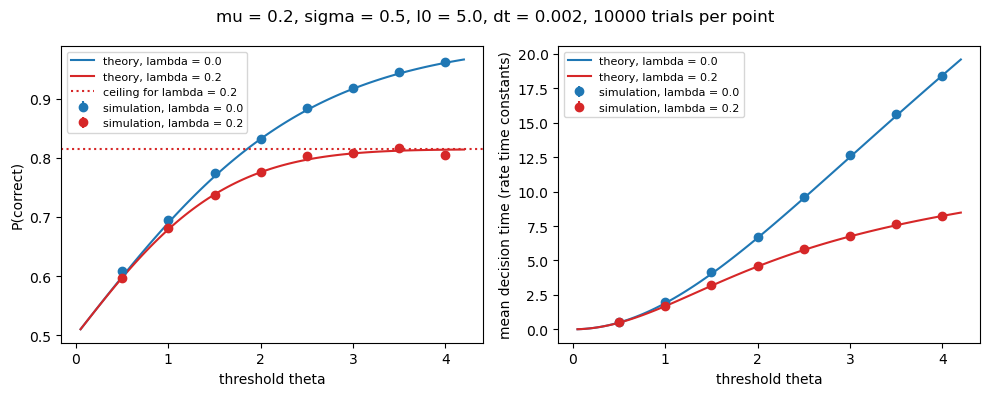

In [7]:

# Figure: accuracy and mean decision time vs threshold

theta_fine = np.linspace(0.05, 4.2, 100)    # smooth x-axis for the theory curves
colors = {0.0: "tab:blue", 0.2: "tab:red"}

plt.figure(figsize=(10, 4))
for lam in lambdas:
    c = colors[lam]

    # theory curves
    if lam == 0:
        acc_curve, time_curve = theory_b(theta_fine)
    else:
        acc_curve = [theory_c(lam, th)[0] for th in theta_fine]
        time_curve = [theory_c(lam, th)[1] for th in theta_fine]

    # simulation points
    sim_acc = [results[(lam, th)][0] for th in thetas]
    sim_acc_err = [results[(lam, th)][1] for th in thetas]
    sim_time = [results[(lam, th)][2] for th in thetas]
    sim_time_err = [results[(lam, th)][3] for th in thetas]

    plt.subplot(1, 2, 1)
    plt.plot(theta_fine, acc_curve, color=c, label=f"theory, lambda = {lam}")
    plt.errorbar(thetas, sim_acc, yerr=sim_acc_err, fmt="o", color=c, label=f"simulation, lambda = {lam}")

    plt.subplot(1, 2, 2)
    plt.plot(theta_fine, time_curve, color=c, label=f"theory, lambda = {lam}")
    plt.errorbar(thetas, sim_time, yerr=sim_time_err, fmt="o", color=c, label=f"simulation, lambda = {lam}")

plt.subplot(1, 2, 1)
plt.axhline(ceiling, color="tab:red", linestyle=":", label="ceiling for lambda = 0.2")
plt.xlabel("threshold theta")
plt.ylabel("P(correct)")
plt.legend(fontsize=8)

plt.subplot(1, 2, 2)
plt.xlabel("threshold theta")
plt.ylabel("mean decision time (rate time constants)")
plt.legend(fontsize=8)

plt.suptitle(f"mu = {mu}, sigma = {sigma}, I0 = {I0}, dt = {dt}, {n_trials} trials per point")
plt.tight_layout()

plt.show()